# 07 · Mixture of Experts over all matchers + final results

**Course topic: Mixture of Experts.** The matchers from 04–06 are the **experts**. A gating network
picks, per pair, how much to trust each expert: p = σ(Σᵢ wᵢ(x) · (aᵢ zᵢ + bᵢ)), with w(x) = softmax(gate(x)).
The gate sees *record properties*: script, source, empty address, lengths, retrieval scores.
**It never sees the country label**, so an unseen country is routed by its script and data quality.
Trained on **part B** (pairs that no expert was trained on).

Compared with: the mean of calibrated experts, logistic-regression stacking, MoE with a constant gate
(learned weights that don't depend on the input, an ablation), and LightGBM stacking on the same inputs.

Then it builds the **final results table and charts** from every attached notebook.

**Run on Kaggle:** *Settings → Accelerator: None (CPU), Internet: On.* Inputs: the dataset, the output of `03_candidates`, and the outputs of every model notebook you ran (04, 05a–c, 06a–f; 01 and 02 optional).
Then *Save Version → Save & Run All*. Results are in the notebook's **Output** tab, and later
notebooks take that output as an input.
Set `QUICK_RUN = True` first for a short check run.

In [5]:
# ==== Setup (Kaggle: Settings -> Internet ON; GPU T4 where the notebook needs one) ====
import os, sys, subprocess, importlib, time, json, math, re, random, gc, unicodedata, collections, csv, hashlib, glob, zlib
from pathlib import Path
for mod, pip in [('anyascii', 'anyascii'), ('lightgbm', 'lightgbm'), ('sklearn', 'scikit-learn'), ('matplotlib', 'matplotlib')]:
    try: importlib.import_module(mod)
    except ImportError:
        if subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pip]).returncode != 0: print('WARNING: could not install', pip)
import numpy as np, pandas as pd
from anyascii import anyascii
import warnings; warnings.filterwarnings('ignore', category=FutureWarning); warnings.filterwarnings('ignore', category=UserWarning)
import torch, torch.nn as nn, torch.nn.functional as F
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = DEVICE == 'cuda'
print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '(CPU)')
_T0 = time.time()
def log(*a): print(f'[{(time.time() - _T0) / 60:6.1f} min]', *a, flush=True)

device: cpu (CPU)


In [6]:
# ==== Configuration ====
QUICK_RUN = False      # True = tiny sample (3,000 / 600 / 600 S1) to check the notebook runs; False = real run
PREP_MODE = 'load'         # 'build' = make records from the raw split, 'build_save' = also save them, 'load' = take them from 03_candidates

CFG = dict(SEED=42, B_FRAC=0.15, K_TFIDF=10, K_DENSE=10, K_FINAL=5, MAX_LEN=96, SUBSAMPLE_S1=None, EXCLUDE_EXPERTS=['Siamese char-BiRNN (vanilla)'], MOE_EPOCHS=30)
if QUICK_RUN:
    CFG.update(SUBSAMPLE_S1={'train': 3000, 'val': 600, 'test': 600}, )
if os.environ.get('NLP_ER_SMOKE') == '1':                         # local smoke test only
    CFG.update(json.loads(os.environ.get('NLP_ER_CFG', '{}')))
SEED = CFG['SEED']
random.seed(SEED); np.random.seed(SEED)
try: torch.manual_seed(SEED)
except NameError: pass

INPUT_ROOT = Path(os.environ.get('NLP_ER_INPUT', '/kaggle/input'))
OUT = Path(os.environ.get('NLP_ER_OUT', '/kaggle/working'))
for d in ('prep', 'scores', 'results', 'preds'): (OUT / d).mkdir(parents=True, exist_ok=True)

def find_all(pattern):
    return sorted(Path(p) for p in glob.glob(str(INPUT_ROOT / '**' / pattern), recursive=True))
def find_one(pattern):
    h = find_all(pattern); return h[0] if h else None

_d = find_one('train/train_source1.tsv')
assert _d is not None, 'Add the dataset (folder with train/ val/ test/ test_labels/) as an input of this notebook'
DATA = _d.parent.parent
print('data:', DATA, '| output:', OUT)

data: /kaggle/input/datasets/akshatiit/er-small | output: /kaggle/working


In [7]:
# ==== Records: load the split, normalise, learn the transliteration lexicon ====
def h01(key):          # uniform [0,1) hash (BLAKE2b; CRC32 hashes of the same id are correlated)
    return int.from_bytes(hashlib.blake2b(key.encode(), digest_size=8).digest(), 'big') / 2**64

def read_tsv(p):
    return pd.read_csv(p, sep='\t', dtype=str, keep_default_na=False, quoting=csv.QUOTE_NONE, encoding='utf-8')

def read_gt(p):
    g = read_tsv(p)
    return {s: [x for x in m.split(',') if x] for s, m in zip(g.source1_entity_id, g.matched_entity_ids)}

SPLITS = ['train', 'val', 'test']
ABBR = {'pvt': 'private', 'ltd': 'limited', 'co': 'company', 'corp': 'corporation', 'inc': 'incorporated',
        'intl': 'international', 'mfg': 'manufacturing', 'svcs': 'services', 'svc': 'service', 'bros': 'brothers',
        'assoc': 'associates', 'mgmt': 'management', 'tech': 'technologies', 'rd': 'road', 'st': 'street',
        'str': 'street', 'ave': 'avenue', 'av': 'avenue', 'blvd': 'boulevard', 'dr': 'drive', 'ln': 'lane',
        'ct': 'court', 'pl': 'place', 'hwy': 'highway', 'pkwy': 'parkway', 'sq': 'square', 'ste': 'suite',
        'apt': 'apartment', 'fl': 'floor', 'bldg': 'building', 'nr': 'near', 'opp': 'opposite', 'cir': 'circle',
        'ter': 'terrace', 'mkt': 'market', 'ngr': 'nagar', 'clny': 'colony'}
LEGAL = {'private', 'limited', 'llp', 'llc', 'incorporated', 'corporation', 'company', 'the', 'plc', 'opc', 'and'}
SCRIPTS = ['latin', 'devanagari', 'malayalam', 'other_indic']
_PUNCT = re.compile(r"[^\w\s/-]+")
INDIC_FIX = [('റ്റ', 'ട്ട')]        # Malayalam ṟṟa: anyascii gives 'rr' where English has 't' (limirrd -> limittd)
_MG = re.compile(r'mg\b')            # anusvara before g: 'marketimg' -> 'marketing'

def romanise(s):
    if s.isascii(): return s
    for a, b in INDIC_FIX: s = s.replace(a, b)
    return _MG.sub('ng', anyascii(s))

def norm(s, expand=True, roman=True, lex=None):
    s = unicodedata.normalize('NFKC', s)
    if roman and not s.isascii(): s = romanise(s)
    toks = _PUNCT.sub(' ', s.lower().replace('&', ' and ')).split()
    if lex: toks = [lex.get(t, t) for t in toks]
    if expand: toks = [ABBR.get(t, t) for t in toks]
    return ' '.join(toks)

def script_of(s):
    if s.isascii(): return 'latin'
    kinds = set()
    for ch in s:
        o = ord(ch)
        if 0x0900 <= o <= 0x097F: kinds.add('devanagari')
        elif 0x0D00 <= o <= 0x0D7F: kinds.add('malayalam')
        elif 0x0980 <= o <= 0x0DFF: kinds.add('other_indic')
    for k in ('devanagari', 'malayalam', 'other_indic'):
        if k in kinds: return k
    return 'latin'                               # accented Latin (e.g. French) counts as Latin

def build_rec():
    parts = []
    for sp in SPLITS:
        for src in ('source1', 'source2', 'source3'):
            d = read_tsv(DATA / sp / f'{sp}_{src}.tsv'); d['split'] = sp; d['src'] = 'S' + src[-1]; parts.append(d)
    R = pd.concat(parts, ignore_index=True).rename(columns={'entity_id': 'id', 'business_name': 'name', 'business_address': 'addr'})
    if CFG['SUBSAMPLE_S1']:          # keep n S1 per split + their records + the same share of unlinked records
        keep = set()
        for sp, n in CFG['SUBSAMPLE_S1'].items():
            g = read_gt(DATA / ('test_labels' if sp == 'test' else sp) / f'{sp}_ground_truth.tsv')   # row selection only
            s1 = R.id[(R.split == sp) & (R.src == 'S1')]
            ks = set(s1.sample(min(n, len(s1)), random_state=SEED)); keep |= ks
            owner = {x: s for s, l in g.items() for x in l}; frac = len(ks) / len(s1)
            for x in R.id[(R.split == sp) & (R.src != 'S1')]:
                o = owner.get(x)
                if (o in ks) if o is not None else (h01(f'sub|{x}') < frac): keep.add(x)
        R = R[R.id.isin(keep)].reset_index(drop=True)
    R['script'] = [script_of(a + ' ' + b) for a, b in zip(R.name, R.addr)]
    return R

def learn_lexicon(R, owner, min_n=3, min_share=0.6):
    # romanised non-Latin word -> English word, aligned by position in linked name pairs of train part A
    ix = pd.Series(np.arange(len(R)), index=R.id.values)
    cnt = collections.defaultdict(collections.Counter)
    for i in np.where((R.split.values == 'train') & (R.src.values != 'S1') & (R.script.values != 'latin'))[0]:
        o = owner.get(R.id.values[i])
        if o is None or h01(f'AB{SEED}|{o}') < CFG['B_FRAC']: continue              # part B excluded
        a = norm(R.name.values[i], expand=False).split(); b = norm(R.name.values[ix[o]], expand=False).split()
        if len(a) == len(b):
            for x, y in zip(a, b):
                if x != y and y.isascii(): cnt[x][y] += 1
    lex = {}
    for x, c in cnt.items():
        y, n = c.most_common(1)[0]
        if n >= min_n and n / sum(c.values()) >= min_share: lex[x] = y
    return lex

def norm_rec(s, expand=True): return norm(s, expand=expand, lex=None if s.isascii() else LEX)
def ce_text(name, addr):
    n = name if name.isascii() else f'{name} / {norm_rec(name, expand=False)}'
    a = addr if addr.isascii() else romanise(addr)
    return f'{n} | {a if a.strip() else "-"}'
def add_text_cols(R):          # every derived text column the matchers read
    R['nn'] = R.name.map(norm_rec); R['na'] = R.addr.map(norm_rec)
    R['ncore'] = [' '.join(t for t in x.split() if t not in LEGAL) or x for x in R.nn]
    R['ce_text'] = [ce_text(a, b) for a, b in zip(R.name, R.addr)]
    R['ltext'] = (R.nn + ' | ' + R.na).str.slice(0, 100)
    R['bl_text'] = R.nn + ' ' + R.na
    return R

if PREP_MODE == 'load':
    _p = find_one('prep/rec.parquet')
    assert _p is not None, 'Add the output of notebook 03_candidates as an input of this notebook'
    REC = pd.read_parquet(_p); PREP_DIR = _p.parent
    LEX = json.load(open(PREP_DIR / 'translit_lexicon.json'))
    _meta = json.load(open(PREP_DIR / 'prep_meta.json'))
    if _meta.get('quick') != QUICK_RUN: print(f"NOTE: 03_candidates ran with QUICK_RUN={_meta.get('quick')}; its sample is used")
    CFG.update({k: _meta['cfg'][k] for k in ('K_TFIDF', 'K_DENSE', 'K_FINAL', 'B_FRAC', 'SEED')})
else:
    REC = build_rec()
    _gt = read_gt(DATA / 'train' / 'train_ground_truth.tsv')
    LEX = learn_lexicon(REC, {x: s for s, l in _gt.items() for x in l})
    print(f'transliteration lexicon: {len(LEX):,} words, e.g.', dict(list(LEX.items())[:12]))
    REC = add_text_cols(REC)
    if PREP_MODE == 'build_save':
        REC.to_parquet(OUT / 'prep' / 'rec.parquet')
        json.dump(LEX, open(OUT / 'prep' / 'translit_lexicon.json', 'w'), ensure_ascii=False)
        json.dump({'quick': QUICK_RUN, 'cfg': CFG, 'n': len(REC)}, open(OUT / 'prep' / 'prep_meta.json', 'w'), indent=1)

ID2IX = pd.Series(np.arange(len(REC)), index=REC.id.values)
_s1 = set(REC.id[REC.src == 'S1'])
GT = {sp: {s: l for s, l in read_gt(DATA / sp / f'{sp}_ground_truth.tsv').items() if s in _s1} for sp in ('train', 'val')}
OWNER = {sp: {x: s for s, l in GT[sp].items() for x in l} for sp in ('train', 'val')}
print(REC.groupby(['split', 'src', 'country']).size().unstack([1, 2]).to_string())

src         S1            S2            S3       
country  India     US  India     US  India     US
split                                            
test     11176  10353  25644  23835  27220  24875
train    39115  36238  90184  82873  94663  87657
val       5588   5176  12852  12044  13515  12341


In [8]:
# ==== Metric (macro F0.5 per S1, singletons included), decision rule, result files ====
def f05_parts(tp, npred, ntrue):
    P = np.divide(tp, npred, out=np.zeros(len(tp)), where=npred > 0)
    R = np.divide(tp, ntrue, out=np.zeros(len(tp)), where=ntrue > 0)
    d = 0.25 * P + R
    f = np.divide(1.25 * P * R, d, out=np.zeros(len(tp)), where=d > 0)
    return np.where(ntrue == 0, (npred == 0).astype(float), f), P, R

class Evaluator:
    def __init__(self, sp, gt):
        self.s1 = REC.id.values[(REC.split.values == sp) & (REC.src.values == 'S1')]
        self.pos = pd.Series(np.arange(len(self.s1)), index=self.s1)
        self.ntrue = np.array([len(gt.get(s, [])) for s in self.s1])
        self.owner = {x: s for s, l in gt.items() for x in l}
        self.country = REC.country.values[ID2IX[self.s1].values]
    def links(self, q_ids, s_ids):
        si = self.pos[s_ids].values if len(s_ids) else np.zeros(0, int)
        return si, np.array([self.owner.get(q) == s for q, s in zip(q_ids, s_ids)], float)
    def metrics(self, si, ok):
        n = len(self.s1); npred = np.bincount(si, minlength=n); tp = np.bincount(si, weights=ok, minlength=n)
        f, P, R = f05_parts(tp, npred, self.ntrue)
        out = {'f05': f.mean(), 'P': P[npred > 0].mean() if (npred > 0).any() else 0.0,
               'R': R[self.ntrue > 0].mean() if (self.ntrue > 0).any() else 0.0,
               'singleton_acc': (npred[self.ntrue == 0] == 0).mean() if (self.ntrue == 0).any() else float('nan')}
        for c in np.unique(self.country): out[f'f05_{c}'] = f[self.country == c].mean()
        return out
    def tune(self, best, grid=np.round(np.arange(0.05, 0.991, 0.01), 3)):
        si, ok = self.links(best.q_id.values, best.s_id.values); p = best.p.values
        curve = [(t, self.metrics(si[p >= t], ok[p >= t])['f05']) for t in grid]
        t, f = max(curve, key=lambda x: x[1]); return t, f, curve
    def at(self, best, thr):
        sel = best.p.values >= thr
        return self.metrics(*self.links(best.q_id.values[sel], best.s_id.values[sel]))

_EV = {}
def ev(sp):                                      # test labels are read ONLY here, for the final scoring
    if sp not in _EV:
        g = GT[sp] if sp != 'test' else read_gt(DATA / 'test_labels' / 'test_ground_truth.tsv')
        _EV[sp] = Evaluator(sp, {s: l for s, l in g.items() if s in _s1})
    return _EV[sp]

def best_per_record(pairs, p):                   # decision rule: every S2/S3 record -> its best S1 candidate
    d = pd.DataFrame({'q': pairs.qi.values, 'p': p, 'q_id': pairs.q_id.values, 's_id': pairs.s_id.values})
    return d.sort_values(['q', 'p'], ascending=[True, False]).drop_duplicates('q')

def sigmoid(x): return 1 / (1 + np.exp(-np.clip(x, -30, 30)))
def safe_name(s): return re.sub(r'[^\w.-]+', '_', s)

def report(section, method, p_val, p_test, **extra):
    # threshold tuned on val; test scored once; writes results/<method>.json and preds/<method>/matching_results.tsv
    thr, f_val, _ = ev('val').tune(best_per_record(PAIRS['val'], p_val))
    bt = best_per_record(PAIRS['test'], p_test); m = ev('test').at(bt, thr)
    row = {'section': section, 'method': method, 'threshold': thr, 'val_f05': round(f_val, 5),
           'test_f05': round(m['f05'], 5), 'test_P': round(m['P'], 4), 'test_R': round(m['R'], 4),
           'test_singleton_acc': round(m['singleton_acc'], 4), 'quick': QUICK_RUN,
           **{k.replace('f05_', 'test_f05_'): round(v, 5) for k, v in m.items() if k.startswith('f05_')}, **extra}
    json.dump(row, open(OUT / 'results' / f'{safe_name(method)}.json', 'w'), indent=1, default=str)
    sel = bt[bt.p >= thr]; grp = sel.groupby('s_id').q_id.apply(lambda x: ','.join(x))
    s1 = REC.id.values[(REC.split.values == 'test') & (REC.src.values == 'S1')]
    d = OUT / 'preds' / safe_name(method); d.mkdir(exist_ok=True)
    pd.DataFrame({'source1_entity_id': s1, 'matched_entity_ids': grp.reindex(s1).fillna('').values}).to_csv(
        d / 'matching_results.tsv', sep='\t', index=False)
    print(f"{method}: threshold {thr:.2f} | val F0.5 {f_val:.5f} | TEST F0.5 {m['f05']:.5f}  P {m['P']:.4f}  R {m['R']:.4f}  "
          + ' '.join(f"{k[4:]} {v:.4f}" for k, v in m.items() if k.startswith('f05_')))
    return row

def save_scores(method, d):                      # all matchers save LOGITS for B / val / test pairs
    for k, v in d.items(): np.save(OUT / 'scores' / f'{safe_name(method)}_{k}.npy', np.asarray(v, np.float32))

def load_pairs():
    base = OUT / 'prep' if (OUT / 'prep' / 'pairs_test.parquet').exists() else find_one('prep/pairs_test.parquet').parent
    P = {sp: pd.read_parquet(base / f'pairs_{sp}.parquet') for sp in SPLITS}
    P['A'] = P['train'][P['train'].part == 'A'].reset_index(drop=True)
    P['B'] = P['train'][P['train'].part == 'B'].reset_index(drop=True)
    return P

In [9]:
PAIRS = load_pairs()
print({sp: f"{len(PAIRS[sp]):,} pairs" + (f", positive rate {PAIRS[sp].label.mean():.3f}" if 'label' in PAIRS[sp] else '')
       for sp in ('A', 'B', 'val', 'test')})

{'A': '1,509,720 pairs, positive rate 0.147', 'B': '267,165 pairs, positive rate 0.146', 'val': '253,760 pairs, positive rate 0.147', 'test': '507,870 pairs'}


In [10]:
# ==== Collect expert scores from the attached notebooks ====
RES = {}
for p in find_all('results/*.json'):
    r = json.load(open(p)); RES[r['method']] = r
EXPERTS, Z = [], {s: [] for s in ('B', 'val', 'test')}
for m, r in RES.items():
    if m in CFG['EXCLUDE_EXPERTS']: continue
    f = {s: find_one(f'scores/{safe_name(m)}_{s}.npy') for s in ('B', 'val', 'test')}
    if all(f.values()):
        arr = {s: np.asarray(np.load(f[s]), dtype=np.float32).reshape(-1) for s in f}
        if all(len(arr[s]) == len(PAIRS[s]) for s in arr) and all(np.all(np.isfinite(arr[s])) for s in arr):
            EXPERTS.append(m); [Z[s].append(arr[s]) for s in arr]
        else: print('skip (pair count differs or non-finite values, other QUICK_RUN setting?):', m)
print('experts:', EXPERTS)
assert len(EXPERTS) >= 2, 'attach the outputs of at least two model notebooks'
Z = {s: np.stack(v, 1) for s, v in Z.items()}
mu, sd = Z['B'].mean(0), Z['B'].std(0) + 1e-6; Z = {s: (v - mu) / sd for s, v in Z.items()}

NUM_RE = re.compile(r'\d+')
def gate_features(P):
    c = lambda col: REC[col].values[P.qi.values]
    G = [(c('script') == s_).astype(np.float32) for s_ in SCRIPTS]
    G += [(c('src') == 'S3').astype(np.float32), (c('na') == '').astype(np.float32),
          np.array([bool(NUM_RE.search(x)) for x in c('na')], np.float32),
          np.array([len(x) for x in c('nn')], np.float32) / 40, np.array([len(x) for x in c('na')], np.float32) / 80,
          P.tf_cos.values.astype(np.float32), P.de_cos.values.astype(np.float32),
          P.rrf_rank.values.astype(np.float32) / CFG['K_FINAL'], P.n_cand.values.astype(np.float32) / CFG['K_FINAL']]
    return np.stack(G, 1)

GF = {s: gate_features(PAIRS[s]) for s in ('B', 'val', 'test')}
gm, gs = GF['B'].mean(0), GF['B'].std(0) + 1e-6; GF = {s: (v - gm) / gs for s, v in GF.items()}
yB = PAIRS['B'].label.values

experts: ['CE bge-reranker-base zero-shot', 'CE bge-reranker-base full fine-tune', 'GBM (string + parsed-address features)', 'CE bge-reranker-base LoRA r=16', 'Siamese char-BiLSTM', 'Siamese char-BiGRU', 'CE bge-reranker-base + MoE head (top-2 of 4)', 'CE IndicBERTv2 full fine-tune', 'CE mDeBERTa-v3 full fine-tune (fp32)']


In [11]:
# ==== Fusion methods ====
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb
torch.manual_seed(SEED)

class GatedMoE(nn.Module):
    def __init__(self, n_exp, n_feat, input_gate=True):
        super().__init__()
        self.a = nn.Parameter(torch.ones(n_exp)); self.b = nn.Parameter(torch.zeros(n_exp)); self.c = nn.Parameter(torch.zeros(1))
        self.input_gate = input_gate; self.w0 = nn.Parameter(torch.zeros(n_exp))
        self.gate = nn.Sequential(nn.Linear(n_feat, 32), nn.ReLU(), nn.Linear(32, n_exp)) if input_gate else None
    def forward(self, z, g):
        w = self.gate(g).softmax(-1) if self.input_gate else self.w0.softmax(-1).expand(len(z), -1)
        return (w * (self.a * z + self.b)).sum(-1) + self.c, w

def fit_moe(input_gate, cal):
    # experts' affine calibration starts from their own logistic fits -> training starts at the "mean of calibrated experts"
    torch.manual_seed(SEED); m = GatedMoE(Z['B'].shape[1], GF['B'].shape[1], input_gate)
    with torch.no_grad():
        m.a.copy_(torch.tensor([c.coef_[0, 0] for c in cal], dtype=torch.float32))
        m.b.copy_(torch.tensor([c.intercept_[0] for c in cal], dtype=torch.float32))
    Zt, Gt, yt = (torch.as_tensor(a, dtype=torch.float32) for a in (Z['B'], GF['B'], yB))
    bs = 2048; per_ep = math.ceil(len(Zt) / bs); steps = max(CFG['MOE_EPOCHS'] * per_ep, 2000)
    opt = torch.optim.Adam(m.parameters(), lr=1e-2, weight_decay=1e-5)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps); st = 0
    while st < steps:
        perm = torch.randperm(len(Zt))
        for a in range(0, len(perm), bs):
            b = perm[a:a + bs]; out, _ = m(Zt[b], Gt[b])
            loss = F.binary_cross_entropy_with_logits(out, yt[b]); opt.zero_grad(); loss.backward(); opt.step(); sch.step()
            st += 1
            if st >= steps: break
    print(f"MoE ({'input' if input_gate else 'constant'} gate): {steps} steps, final batch loss {loss.item():.4f}")
    return m

def moe_predict(m, s):
    with torch.no_grad(): out, w = m(torch.as_tensor(Z[s], dtype=torch.float32), torch.as_tensor(GF[s], dtype=torch.float32))
    return sigmoid(out.numpy()), w.numpy()

cal = [LogisticRegression().fit(Z['B'][:, [i]], yB) for i in range(len(EXPERTS))]
mp = {s: np.mean([c.predict_proba(Z[s][:, [i]])[:, 1] for i, c in enumerate(cal)], 0) for s in ('val', 'test')}
report('8 Fusion', f'Mean of {len(EXPERTS)} calibrated experts', mp['val'], mp['test'])
lr_ = LogisticRegression(max_iter=1000).fit(Z['B'], yB)
report('8 Fusion', 'Logistic-regression stacking', lr_.predict_proba(Z['val'])[:, 1], lr_.predict_proba(Z['test'])[:, 1])
print('LR weights:', dict(zip(EXPERTS, lr_.coef_[0].round(3))))
m0 = fit_moe(False, cal)
report('8 Fusion', 'MoE, constant gate (ablation)', moe_predict(m0, 'val')[0], moe_predict(m0, 'test')[0])
t = time.time(); m1 = fit_moe(True, cal)
pv, _ = moe_predict(m1, 'val'); pt, WT = moe_predict(m1, 'test')
ROW_MOE = report('8 Fusion', 'Gated Mixture of Experts', pv, pt, train_min=round((time.time() - t) / 60, 2), experts=len(EXPERTS))
(OUT / 'models').mkdir(exist_ok=True)                                  # fusion model for 08_demo
torch.save({'experts': EXPERTS, 'state_dict': m1.state_dict(), 'mu': mu.tolist(), 'sd': sd.tolist(), 'gm': gm.tolist(),
            'gs': gs.tolist(), 'n_feat': int(GF['B'].shape[1]), 'threshold': ROW_MOE['threshold']}, OUT / 'models' / 'moe_fusion.pt')
st = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, verbose=-1, random_state=SEED)
st.fit(np.hstack([Z['B'], GF['B']]), yB)
report('8 Fusion', 'LightGBM stacking (same inputs)', st.predict_proba(np.hstack([Z['val'], GF['val']]))[:, 1],
       st.predict_proba(np.hstack([Z['test'], GF['test']]))[:, 1])

short = lambda e: e.replace('CE bge-reranker-base', 'CE').replace(' (string + parsed-address features)', '')
W = pd.DataFrame(WT, columns=[short(e) for e in EXPERTS]); P = PAIRS['test']
W['script'] = REC.script.values[P.qi.values]; W['country'] = REC.country.values[P.qi.values]
GATE_BY_SCRIPT = W.groupby('script').mean(numeric_only=True); GATE_BY_SCRIPT.to_csv(OUT / 'moe_gate_by_script.csv')
GATE_BY_COUNTRY = W.groupby('country').mean(numeric_only=True); GATE_BY_COUNTRY.to_csv(OUT / 'moe_gate_by_country.csv')
print('\nmean gate weight per expert, by script of the S2/S3 record:'); print(GATE_BY_SCRIPT.round(3).T.to_string())
print('\nby country (the gate never sees this label):'); print(GATE_BY_COUNTRY.round(3).T.to_string())

Mean of 9 calibrated experts: threshold 0.30 | val F0.5 0.99525 | TEST F0.5 0.99286  P 0.9941  R 0.9927  India 0.9936 US 0.9920
Logistic-regression stacking: threshold 0.41 | val F0.5 0.99648 | TEST F0.5 0.99477  P 0.9967  R 0.9920  India 0.9962 US 0.9932
LR weights: {'CE bge-reranker-base zero-shot': np.float64(0.051), 'CE bge-reranker-base full fine-tune': np.float64(0.954), 'GBM (string + parsed-address features)': np.float64(4.192), 'CE bge-reranker-base LoRA r=16': np.float64(-0.686), 'Siamese char-BiLSTM': np.float64(-0.059), 'Siamese char-BiGRU': np.float64(0.432), 'CE bge-reranker-base + MoE head (top-2 of 4)': np.float64(-0.421), 'CE IndicBERTv2 full fine-tune': np.float64(0.099), 'CE mDeBERTa-v3 full fine-tune (fp32)': np.float64(2.555)}
MoE (constant gate): 3930 steps, final batch loss 0.0080
MoE, constant gate (ablation): threshold 0.34 | val F0.5 0.99642 | TEST F0.5 0.99474  P 0.9963  R 0.9928  India 0.9964 US 0.9930
MoE (input gate): 3930 steps, final batch loss 0.0065
Ga

             section                                       method  val_f05  test_f05  test_P  test_R  test_f05_US  test_f05_India  test_pair_f1  test_singleton_acc                params  train_min  threshold
5 Classical baseline       GBM (string + parsed-address features)  0.99286   0.99081  0.9938  0.9873      0.98946         0.99205           NaN              0.9857            1609 trees       4.60       0.36
        6 RNN / LSTM                          Siamese char-BiLSTM  0.98920   0.98335  0.9863  0.9846      0.98390         0.98284           NaN              0.9454                 0.73M      13.30       0.06
        6 RNN / LSTM                           Siamese char-BiGRU  0.98814   0.98197  0.9850  0.9835      0.98142         0.98247           NaN              0.9404                 0.68M      13.10       0.15
        6 RNN / LSTM                 Siamese char-BiRNN (vanilla)  0.98374   0.97475  0.9782  0.9789      0.97646         0.97316           NaN              0.9085     

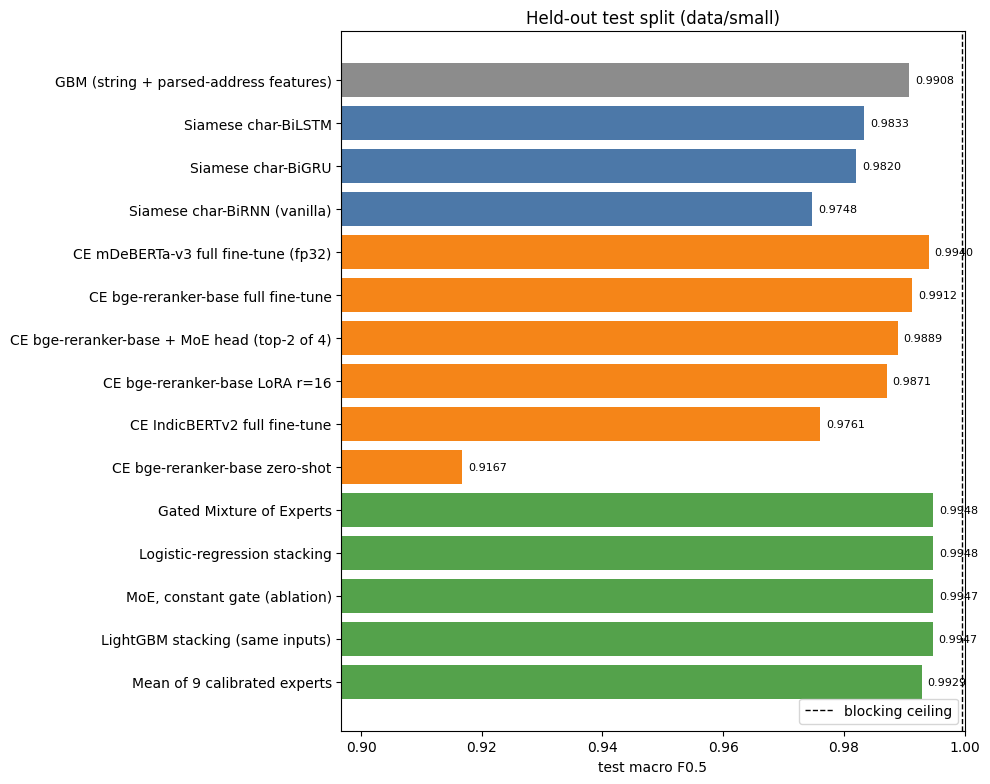

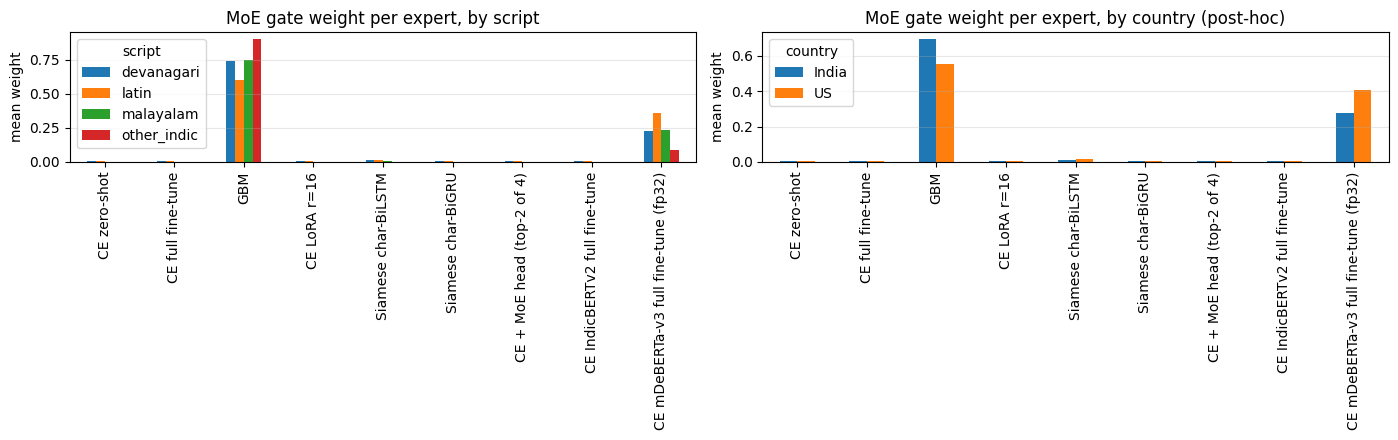

In [12]:
# ==== Final results table + charts ====
import matplotlib.pyplot as plt
for p in find_all('results/*.json') + sorted((OUT / 'results').glob('*.json')):
    r = json.load(open(p)); RES[r['method']] = r
R = pd.DataFrame(RES.values())
if R.quick.astype(str).str.lower().eq('true').any(): print('NOTE: some rows come from QUICK_RUN notebooks:', R[R.quick.astype(str).str.lower() == 'true'].method.tolist())
order = {s: i for i, s in enumerate(['5 Classical baseline', '6 RNN / LSTM', '7 Transformers', '7b Ditto ablation', '8 Fusion'])}
R = R.assign(o=R.section.map(order)).sort_values(['o', 'test_f05'], ascending=[True, False]).drop(columns='o')
cols = [c for c in ['section', 'method', 'val_f05', 'test_f05', 'test_P', 'test_R', 'test_f05_US', 'test_f05_India',
                    'test_pair_f1', 'test_singleton_acc', 'params', 'train_min', 'threshold'] if c in R]
print(R[cols].to_string(index=False)); R[cols].to_csv(OUT / 'final_results.csv', index=False)
bl_p = find_one('blocking.json'); bl = json.load(open(bl_p)) if bl_p else {}
if bl:
    print('\nblocking:'); print(pd.DataFrame(bl['rows']).round(4).to_string(index=False))
    print(f"ceiling F0.5: val {bl['val_ceiling_f05']:.5f} | test {bl['test_ceiling_f05']:.5f} | {bl['pairs_per_record_test']:.2f} candidates per record")
with open(OUT / 'final_results.md', 'w') as f:
    f.write('| ' + ' | '.join(cols) + ' |\n|' + '---|' * len(cols) + '\n')
    for _, r in R[cols].iterrows(): f.write('| ' + ' | '.join('' if pd.isna(r[c]) else str(r[c]) for c in cols) + ' |\n')
    if bl: f.write(f"\nBlocking ceiling (test macro F0.5): {bl['test_ceiling_f05']:.5f}\n")
    for name in ('blocking.json', 'tokenizer_stats.csv', 'tokenization_blocking.csv', 'parser_eval.csv'):
        p = find_one(name)
        if p is not None and name.endswith('.csv'):
            d = pd.read_csv(p)
            try: txt = d.to_markdown(index=False)
            except ImportError: txt = d.to_string(index=False)
            f.write(f'\n### {name}\n\n{txt}\n'); print(f'\n{name}:'); print(d.to_string(index=False))

R = R[R.section != '7b Ditto ablation']                      # the ablation runs have their own table (06g)
fig, ax = plt.subplots(figsize=(10, 0.45 * len(R) + 1.2))
colors = {'5 Classical baseline': '#8c8c8c', '6 RNN / LSTM': '#4C78A8', '7 Transformers': '#F58518', '8 Fusion': '#54A24B'}
ax.barh(R.method, R.test_f05, color=[colors.get(s, '#999') for s in R.section])
if bl: ax.axvline(bl['test_ceiling_f05'], ls='--', c='k', lw=1, label='blocking ceiling'); ax.legend(loc='lower right')
ax.set_xlim(max(0.0, R.test_f05.min() - 0.02), 1.0); ax.invert_yaxis()
for yy, v in enumerate(R.test_f05): ax.text(v + 0.001, yy, f'{v:.4f}', va='center', fontsize=8)
ax.set_xlabel('test macro F0.5'); ax.set_title('Held-out test split (data/small)')
plt.tight_layout(); plt.savefig(OUT / 'results_test_f05.png', dpi=150); plt.show()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
GATE_BY_SCRIPT.T.plot.bar(ax=ax1, title='MoE gate weight per expert, by script')
ax1.set_ylabel('mean weight'); ax1.grid(axis='y', alpha=0.3)
GATE_BY_COUNTRY.T.plot.bar(ax=ax2, title='MoE gate weight per expert, by country (post-hoc)')
ax2.set_ylabel('mean weight'); ax2.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / 'moe_gates.png', dpi=150); plt.show()

## Download the output

The cell below packs everything this notebook wrote into one zip, ready to download from the Output panel.

In [13]:
# ---- Download: pack this notebook's output into one zip --------------------------------------
# Output panel -> refresh -> hover over out_07.zip -> three dots -> Download.
# Keep the session running until the download has finished.
# Later, upload the zip as a Kaggle Dataset and attach it to the notebooks that need it.
import zipfile
ZIP_NAME = 'out_07.zip'
KEEP_PREP = False      # prep/ is shipped only by the notebook that builds it (03; 02 adds parsed_fields)
_zp = OUT / ZIP_NAME
with zipfile.ZipFile(_zp, 'w', zipfile.ZIP_DEFLATED) as zf:
    for f in sorted(OUT.rglob('*')):
        rel = f.relative_to(OUT)
        if not f.is_file() or f.suffix == '.zip' or rel.parts[0].startswith('.'):
            continue
        if rel.parts[0] == 'prep' and not (KEEP_PREP is True or (KEEP_PREP and rel.name in KEEP_PREP)):
            continue
        zf.write(f, rel.as_posix(), compress_type=zipfile.ZIP_STORED if f.suffix in ('.pt', '.safetensors', '.bin', '.npy') else zipfile.ZIP_DEFLATED)
print(f'{_zp}  {_zp.stat().st_size / 2**20:.1f} MiB')
with zipfile.ZipFile(_zp) as zf:
    for i in zf.infolist(): print(f'  {i.file_size / 2**20:8.2f} MiB  {i.filename}')
try:
    from IPython.display import FileLink, display
    display(FileLink(ZIP_NAME))
except Exception:
    pass

/kaggle/working/out_07.zip  2.7 MiB
      0.00 MiB  final_results.csv
      0.00 MiB  final_results.md
      0.01 MiB  models/moe_fusion.pt
      0.00 MiB  moe_gate_by_country.csv
      0.00 MiB  moe_gate_by_script.csv
      0.08 MiB  moe_gates.png
      1.18 MiB  preds/Gated_Mixture_of_Experts/matching_results.tsv
      1.18 MiB  preds/LightGBM_stacking_same_inputs_/matching_results.tsv
      1.18 MiB  preds/Logistic-regression_stacking/matching_results.tsv
      1.18 MiB  preds/Mean_of_9_calibrated_experts/matching_results.tsv
      1.18 MiB  preds/MoE_constant_gate_ablation_/matching_results.tsv
      0.00 MiB  results/Gated_Mixture_of_Experts.json
      0.00 MiB  results/LightGBM_stacking_same_inputs_.json
      0.00 MiB  results/Logistic-regression_stacking.json
      0.00 MiB  results/Mean_of_9_calibrated_experts.json
      0.00 MiB  results/MoE_constant_gate_ablation_.json
      0.14 MiB  results_test_f05.png


/kaggle/working/out_07.zip